# Notebook 04: Time-Series Decomposition & Stationarity Diagnostics
**Project:** Walmart Store Sales Forecasting & Business Intelligence System  
**Phase:** Phase 2 — Exploratory Data Analysis & Time-Series Analysis  
**Author:** Lead Data Scientist & Machine Learning Engineer  

---
### Objectives
1. Perform STL (Seasonal and Trend decomposition using Loess) on aggregate weekly sales.
2. Evaluate trend, annual seasonality (period=52), and residual variance.
3. Conduct statistical stationarity tests (ADF and KPSS) and explain null hypotheses.
4. Detail special investigations: Cold-start series, incomplete panel sparsity, and negative sales.


In [1]:
import os
import sys
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

sys.path.append(os.path.abspath(".."))
from src.data_loader import load_processed_data

plt.rcParams['figure.figsize'] = (12, 6)
sns.set_theme(style="whitegrid", palette="muted")
train, test = load_processed_data()
print("Data loaded successfully.")


2026-11-22 15:10:46,594 [INFO] Loading processed datasets from Parquet: E:\MCA projects\Demand-Forecasting\walmart-recruiting-store-sales-forecasting\data\processed


Data loaded successfully.


## 1. STL Time-Series Decomposition

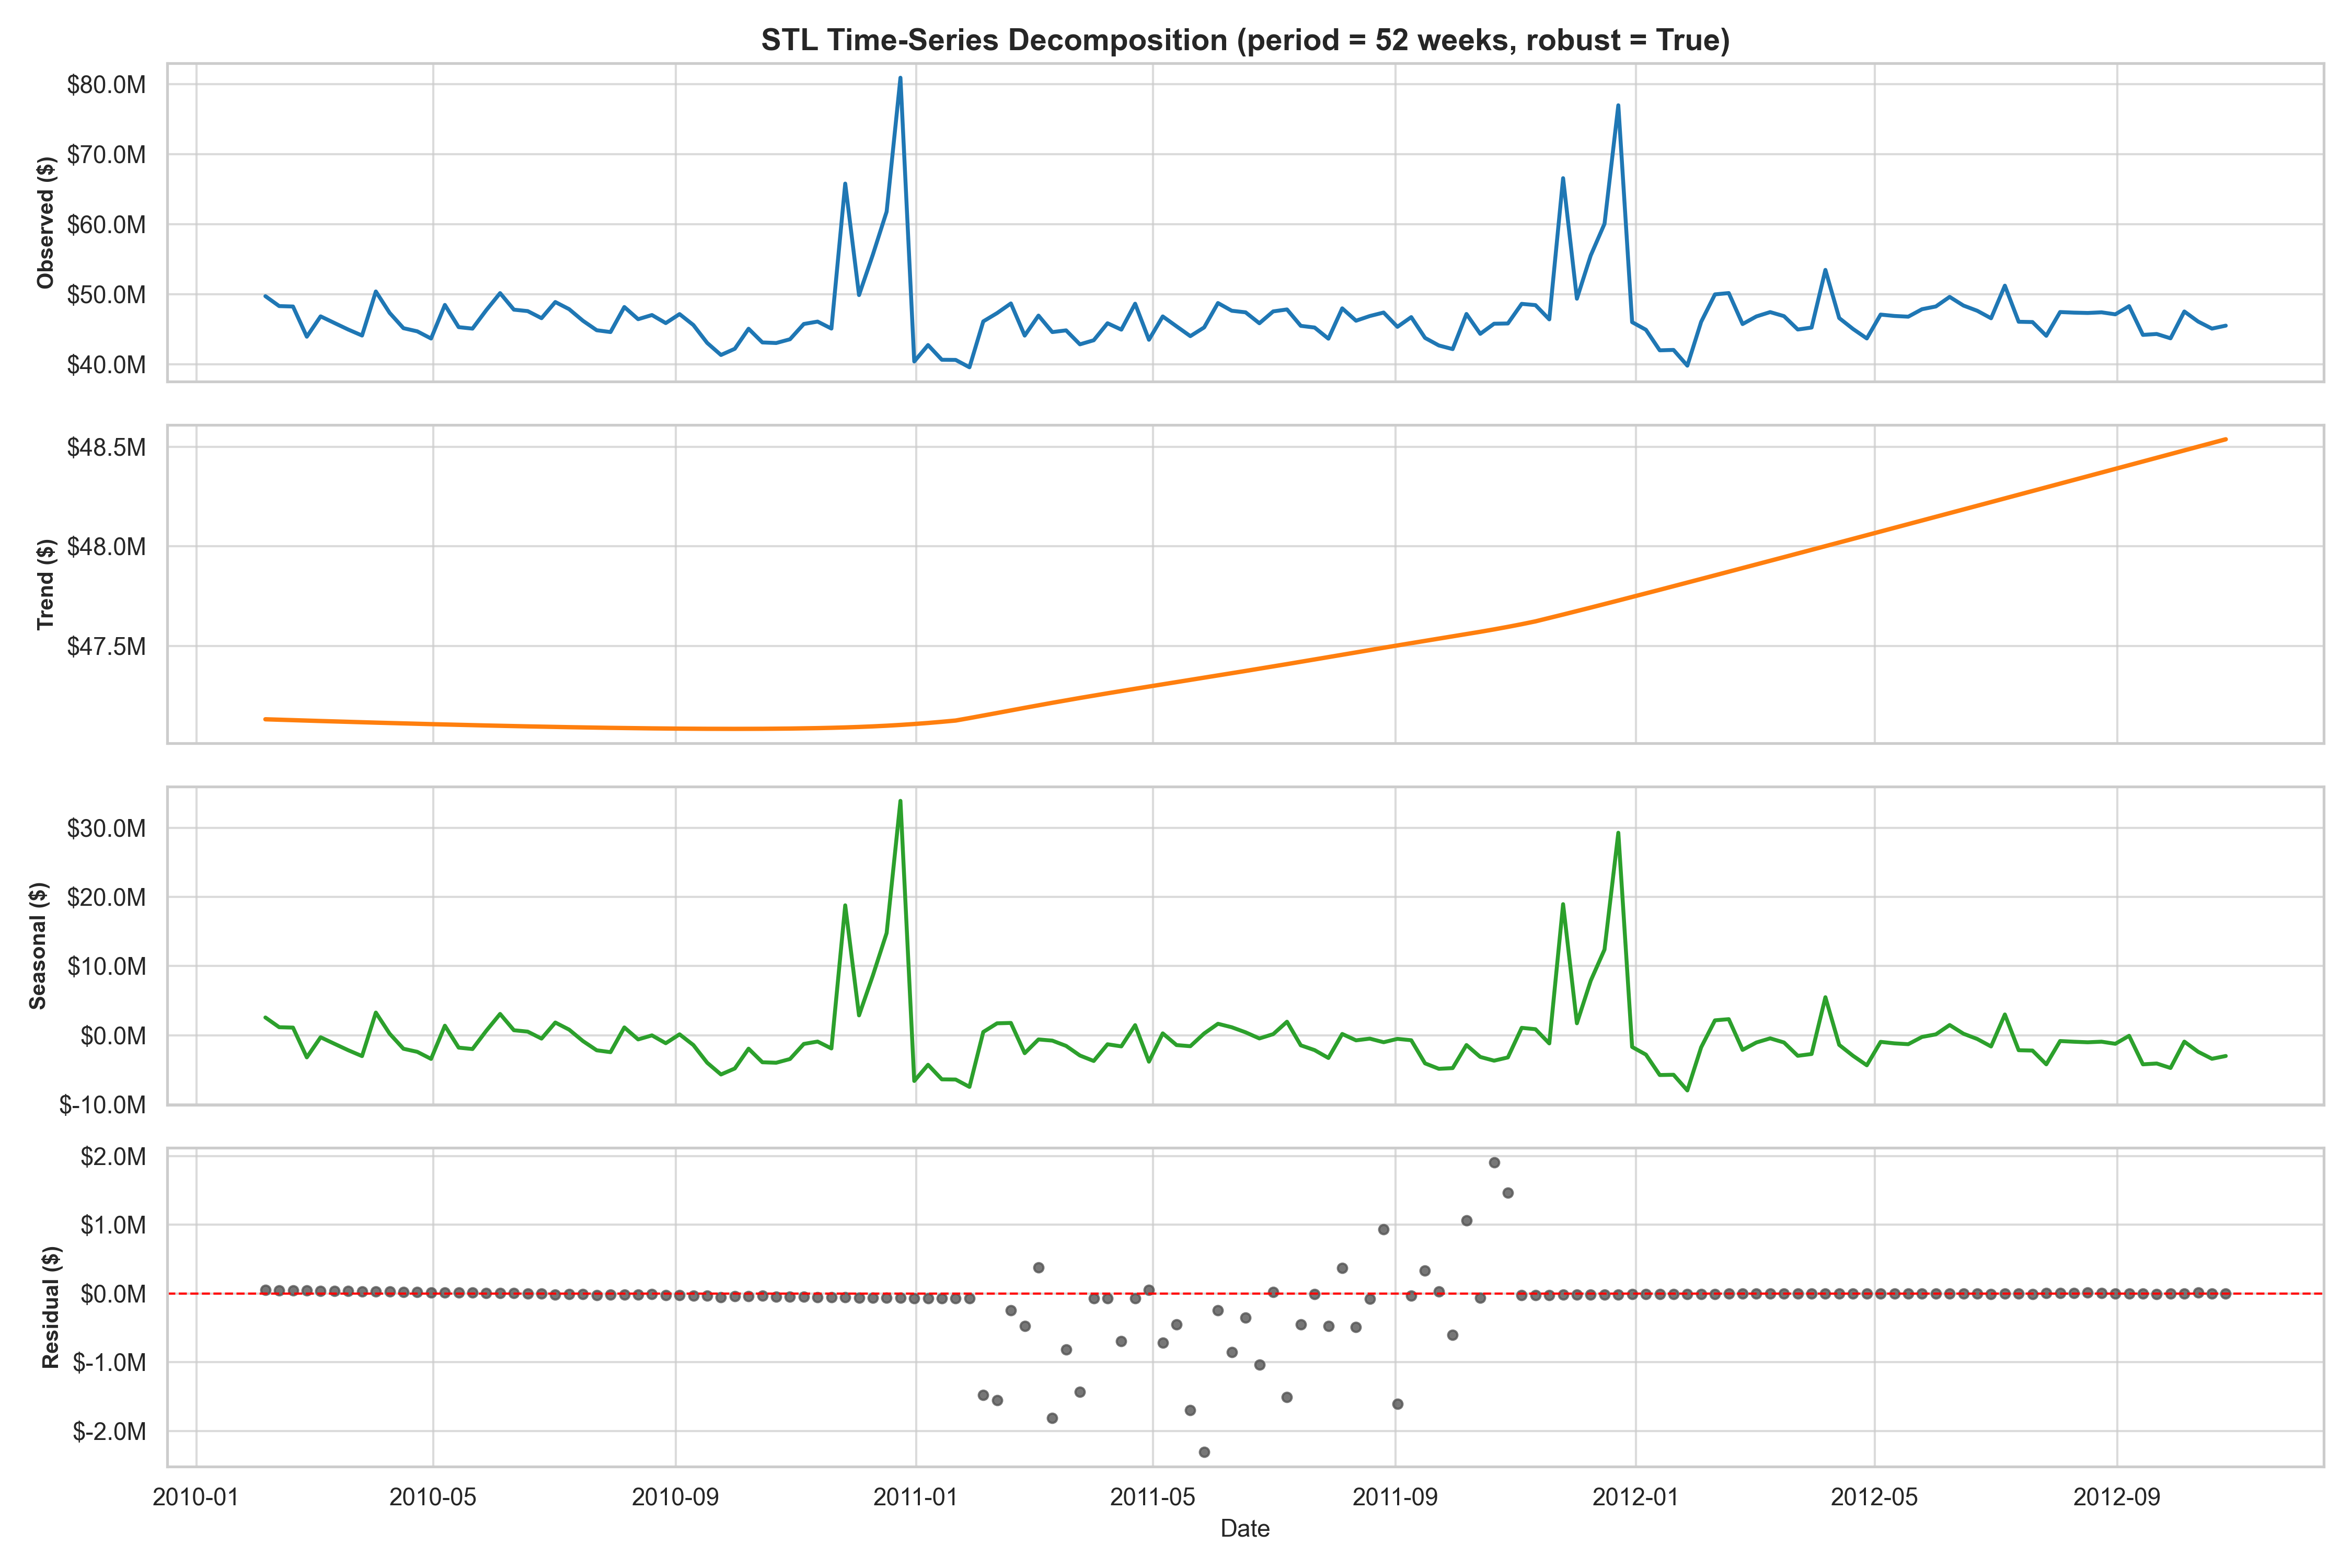

In [2]:
display(Image(filename=os.path.join("..", "outputs", "figures", "fig16_stl_decomposition_aggregate_sales.png")))


## 2. Stationarity Tests (ADF & KPSS)

In [3]:
with open(os.path.join("..", "outputs", "eda", "stationarity_tests.json"), "r") as f:
    stat_tests = json.load(f)

print("=== Augmented Dickey-Fuller (ADF) Test ===")
print("H0: Unit Root Present (Non-Stationary) | H1: Stationary")
print(f"Test Statistic: {stat_tests['ADF']['test_statistic']:.4f}")
print(f"p-value:        {stat_tests['ADF']['p_value']:.4e}")
print(f"Critical Values: {stat_tests['ADF']['critical_values']}")
print(f"Result: Rejects H0 at 1% alpha (Statistically Stationary in Mean)")

print("\n=== Kwiatkowski-Phillips-Schmidt-Shin (KPSS) Test ===")
print("H0: Trend/Level Stationary | H1: Unit Root Present")
print(f"Test Statistic: {stat_tests['KPSS']['test_statistic']:.4f}")
print(f"p-value:        {stat_tests['KPSS']['p_value']:.4f}")
print(f"Critical Values: {stat_tests['KPSS']['critical_values']}")
print(f"Result: Cannot reject H0 (Consistent with Trend/Level Stationarity)")


=== Augmented Dickey-Fuller (ADF) Test ===
H0: Unit Root Present (Non-Stationary) | H1: Stationary
Test Statistic: -5.9083
p-value:        2.6760e-07
Critical Values: {'1%': -3.47864788917503, '5%': -2.882721765644168, '10%': -2.578065326612056}
Result: Rejects H0 at 1% alpha (Statistically Stationary in Mean)

=== Kwiatkowski-Phillips-Schmidt-Shin (KPSS) Test ===
H0: Trend/Level Stationary | H1: Unit Root Present
Test Statistic: 0.0489
p-value:        0.1000
Critical Values: {'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739}
Result: Cannot reject H0 (Consistent with Trend/Level Stationarity)


## 3. Special Investigations: Cold-Start Series in Test Horizon

In [4]:
cold_df = pd.read_csv(os.path.join("..", "outputs", "eda", "cold_start_series_profile.csv"))
print(f"Found {len(cold_df)} (Store, Dept) series in test with zero historical training observations:")
print(cold_df)


Found 11 (Store, Dept) series in test with zero historical training observations:


    Store  Dept Store_Type  Store_Size  Test_Horizon_Weeks First_Test_Date  \
0       5    99          B       34875                   3      2012-11-23   
1       9    99          B      125833                   4      2012-12-07   
2      10    99          B      126512                   6      2012-11-30   
3      18    43          B      120653                   1      2013-04-26   
4      24    43          A      203819                   1      2013-06-21   
5      25    99          B      128107                   2      2012-11-30   
6      34    39          A      158114                   2      2012-11-02   
7      36    30          A       39910                   2      2012-11-02   
8      37    29          C       39910                  12      2012-11-30   
9      42    30          C       39690                   2      2013-02-15   
10     45    39          B      118221                   1      2013-04-26   

   Last_Test_Date                        Recommended_Fallback  

## 4. Special Investigations: Incomplete Panel Sparsity

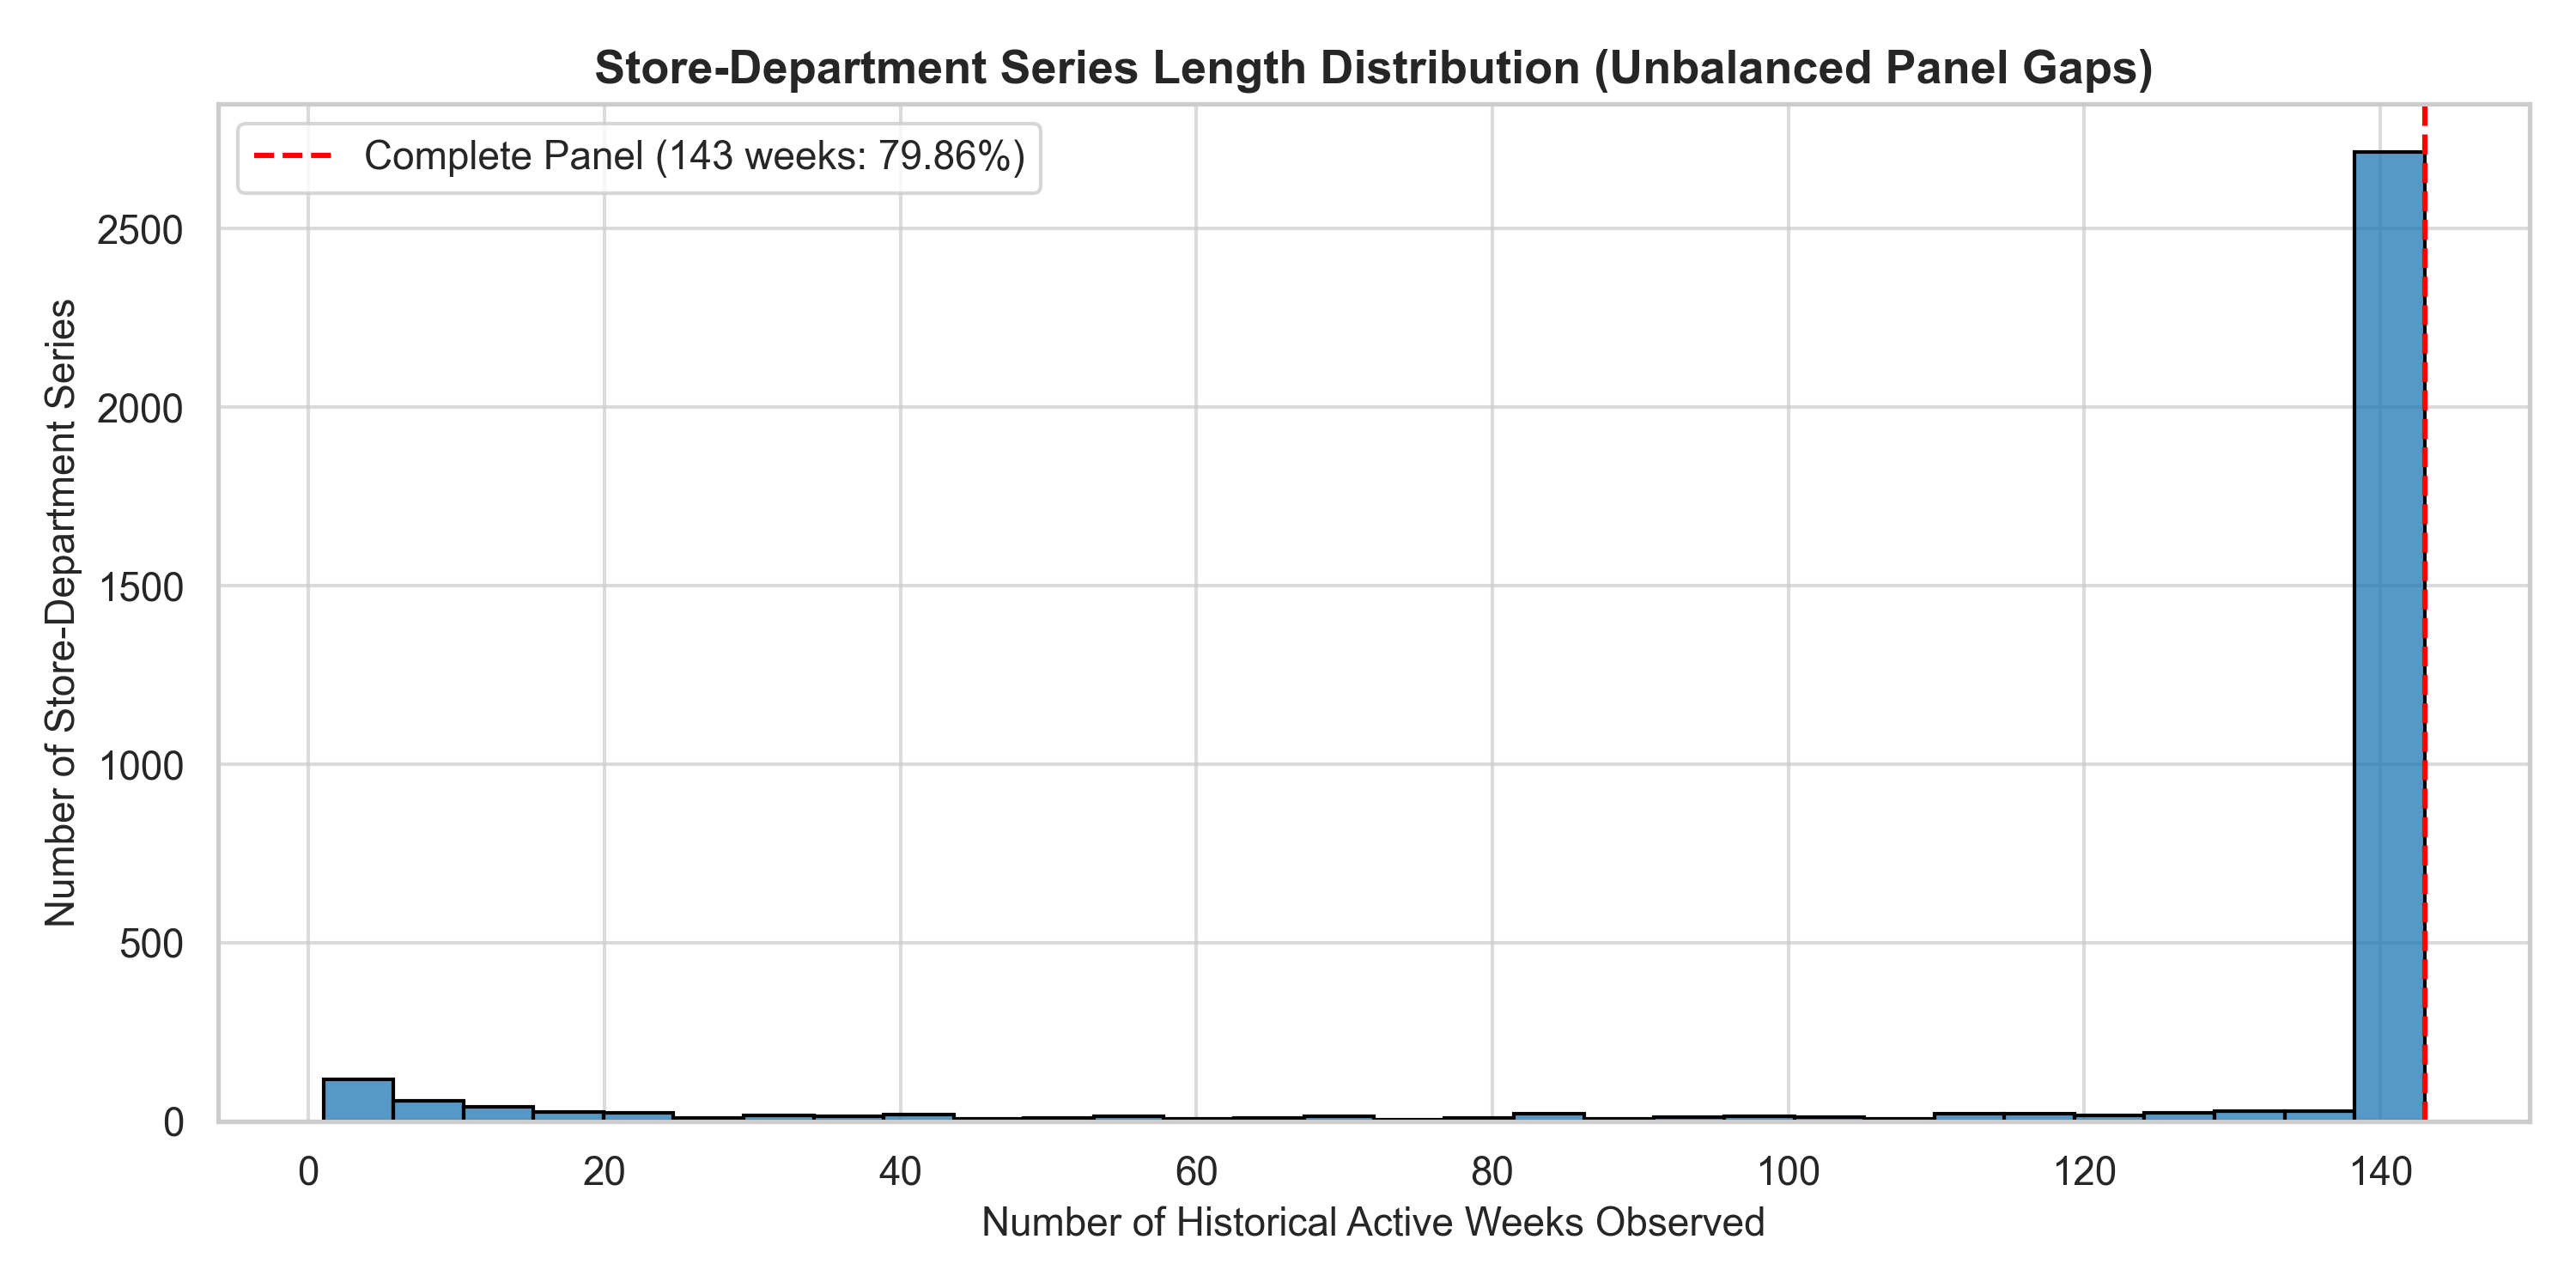

Total Unique (Store, Dept) Series: 3,331
Complete Series (143 weeks):       2,660 (79.86%)
Incomplete Series (< 143 weeks):    671 (20.14%)


In [5]:
display(Image(filename=os.path.join("..", "outputs", "figures", "fig17_panel_sparsity_distribution.png")))

with open(os.path.join("..", "outputs", "eda", "special_investigations_summary.json"), "r") as f:
    spec_sum = json.load(f)

print(f"Total Unique (Store, Dept) Series: {spec_sum['total_active_series_train']:,}")
print(f"Complete Series (143 weeks):       {spec_sum['complete_series_count']:,} ({spec_sum['complete_series_count']/spec_sum['total_active_series_train']*100:.2f}%)")
print(f"Incomplete Series (< 143 weeks):    {spec_sum['incomplete_series_count']:,} ({spec_sum['incomplete_series_count']/spec_sum['total_active_series_train']*100:.2f}%)")
